# Étude de cas 3 — Jalon 2 : apprendre sur le signal brut

Ce notebook compare un CNN 1D entraîné directement sur les fenêtres ECG Holter A à la référence MLP du Jalon 1. Il entraîne ensuite un autoencodeur à retirer du bruit simulé sur Holter A, puis mesure si cela aide le CNN à classer les fenêtres de validation du patch B.

**Données :** les fichiers Holter A et patch B sont présents dans `data/`. Les décisions d’architecture utilisent la validation seulement ; les fichiers test ne sont pas chargés. Le test Holter a déjà été évalué au Jalon 1, ce qui est une limite à déclarer : il ne servira pas ici à choisir ou régler le CNN.


## 1. Vérifier l’environnement

In [3]:
from importlib.metadata import version, PackageNotFoundError
import sys
print('Python utilisé :', sys.executable)
for nom in ['numpy', 'scipy', 'scikit-learn', 'tensorflow', 'matplotlib']:
    try:
        print(f'{nom} : {version(nom)}')
    except PackageNotFoundError:
        print(f'{nom} : ABSENT')


Python utilisé : /home/mapster/ABOUBAKER/SDIA_PRACTICES/SCHOOL/s3-s4/advanced-ai/USECASE_TP/PRACTICE/.venv/bin/python
numpy : 2.5.3
scipy : 1.18.1
scikit-learn : 1.9.1
tensorflow : 2.21.0
matplotlib : 3.11.2


## 2. Charger Holter A et patch B (train et validation uniquement)

Le CNN apprend sur les fenêtres Holter A. Les fenêtres patch B servent plus tard à mesurer le transfert après débruitage. Les deux jeux gardent des patients distincts entre train et validation. Le test n’est pas chargé.


In [5]:
from pathlib import Path
import numpy as np

# Trouver le dossier PRACTICE même si le notebook est lancé depuis notebooks/Jalon2.
candidats = [Path.cwd(), *Path.cwd().parents]
PRACTICE_DIR = next((p for p in candidats if (p / 'data' / 'holter_A').is_dir()), None)
if PRACTICE_DIR is None:
    raise FileNotFoundError('Dossier data/holter_A introuvable ; lancer depuis PRACTICE ou son sous-dossier notebooks.')
DELIVERABLE_DIR = PRACTICE_DIR / 'deliverables' / 'Jalon2'
DELIVERABLE_DIR.mkdir(parents=True, exist_ok=True)

# Chaque fichier NPZ contient déjà les splits ; nous ouvrons seulement train et validation.
with np.load(PRACTICE_DIR / 'data' / 'holter_A' / 'uc3_holterA.npz') as fichier:
    X_A = {s: fichier[f'X_{s}'].copy() for s in ['train', 'val']}
    y_A = {s: fichier[f'classe_{s}'].astype(int) for s in ['train', 'val']}
    patients_A = {s: fichier[f'patient_{s}'].copy() for s in ['train', 'val']}
with np.load(PRACTICE_DIR / 'data' / 'patch_B' / 'uc3_patchB.npz') as fichier:
    X_B = {s: fichier[f'X_{s}'].copy() for s in ['train', 'val']}
    y_B = {s: fichier[f'classe_{s}'].astype(int) for s in ['train', 'val']}
    patients_B = {s: fichier[f'patient_{s}'].copy() for s in ['train', 'val']}

# Vérifier tailles et séparation patient avant tout entraînement.
for nom, Xjeu, yjeu, patients in [('Holter A', X_A, y_A, patients_A), ('Patch B', X_B, y_B, patients_B)]:
    assert all(Xjeu[s].shape == (len(yjeu[s]), 1250) for s in ['train', 'val'])
    assert not (set(np.unique(patients['train'])) & set(np.unique(patients['val'])))
    print(f'{nom} : train {Xjeu["train"].shape}, validation {Xjeu["val"].shape}; patients disjoints.')
    print('  Classes train :', dict(zip(*np.unique(yjeu['train'], return_counts=True))))
    print('  Classes validation :', dict(zip(*np.unique(yjeu['val'], return_counts=True))))


Holter A : train (8400, 1250), validation (1800, 1250); patients disjoints.
  Classes train : {np.int64(0): np.int64(4348), np.int64(1): np.int64(1209), np.int64(2): np.int64(1018), np.int64(3): np.int64(995), np.int64(4): np.int64(830)}
  Classes validation : {np.int64(0): np.int64(892), np.int64(1): np.int64(238), np.int64(2): np.int64(292), np.int64(3): np.int64(198), np.int64(4): np.int64(180)}
Patch B : train (300, 1250), validation (150, 1250); patients disjoints.
  Classes train : {np.int64(0): np.int64(119), np.int64(1): np.int64(69), np.int64(2): np.int64(46), np.int64(3): np.int64(29), np.int64(4): np.int64(37)}
  Classes validation : {np.int64(0): np.int64(67), np.int64(1): np.int64(6), np.int64(2): np.int64(43), np.int64(3): np.int64(9), np.int64(4): np.int64(25)}


## 3. Normaliser les fenêtres et observer un signal

Chaque fenêtre est normalisée séparément : sa moyenne est soustraite et son écart-type sert à la mise à l’échelle. Cela rend les amplitudes comparables. La dernière dimension `1` représente l’unique canal ECG attendu par `Conv1D`. Le CNN s’entraîne sur Holter A ; les données patch sont gardées pour l’expérience de transfert.


Holter A normalisé : (8400, 1250, 1) (1800, 1250, 1)
Patch B normalisé : (300, 1250, 1) (150, 1250, 1)
Moyenne/écart-type de la fenêtre Holter 0 : 0.0 1.0


notebook_jalon2_fr.ipynb:cell6:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


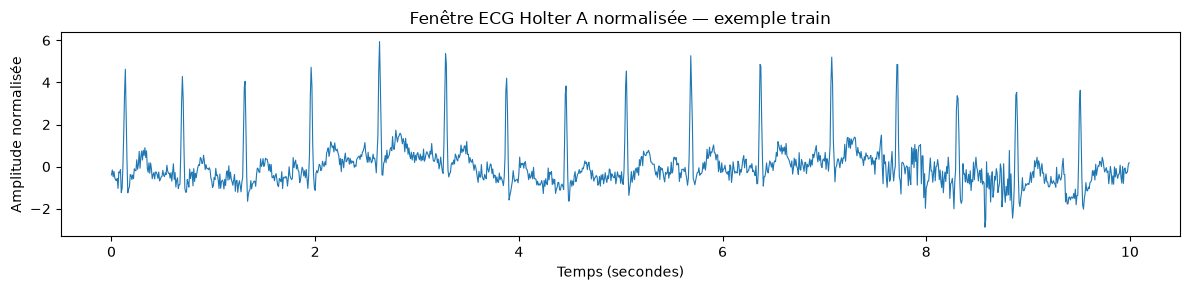

In [7]:
import matplotlib.pyplot as plt

FS = 125  # fréquence d’échantillonnage : 125 mesures par seconde

def normaliser_fenetres(signaux):
    # Les calculs se font le long du temps (axe 1), séparément pour chaque fenêtre.
    signaux = signaux.astype('float32')
    moyenne = signaux.mean(axis=1, keepdims=True)
    ecart_type = signaux.std(axis=1, keepdims=True)
    # Ajouter un canal : (fenêtres, 1 250 mesures) devient (fenêtres, 1 250, 1).
    return ((signaux - moyenne) / (ecart_type + 1e-6))[..., None]

S_A = {s: normaliser_fenetres(X_A[s]) for s in ['train', 'val']}
S_B = {s: normaliser_fenetres(X_B[s]) for s in ['train', 'val']}
# Alias patch pour l’étape finale : la validation patch est l’entrée de l’évaluation de transfert.
S, y = S_B, y_B
print('Holter A normalisé :', S_A['train'].shape, S_A['val'].shape)
print('Patch B normalisé :', S_B['train'].shape, S_B['val'].shape)
print('Moyenne/écart-type de la fenêtre Holter 0 :', round(float(S_A['train'][0].mean()), 3), round(float(S_A['train'][0].std()), 3))

temps = np.arange(1250) / FS
plt.figure(figsize=(12, 3))
plt.plot(temps, S_A['train'][0, :, 0], linewidth=0.8)
plt.title('Fenêtre ECG Holter A normalisée — exemple train')
plt.xlabel('Temps (secondes)'); plt.ylabel('Amplitude normalisée')
plt.tight_layout(); plt.show()


## 4. Vérifier le champ réceptif demandé par le sujet

Le champ réceptif est la portion du signal d’entrée qui peut influencer une activation donnée. Pour chaque convolution de taille `k` et chaque max-pooling de taille 2, le calcul tient compte de l’espacement croissant entre les échantillons représentés.

In [9]:
def calculer_champ_receptif(noyaux, taille_pool=2):
    # r est la largeur observée ; pas est l’écart entre deux positions voisines.
    r, pas = 1, 1
    for k in noyaux:
        r += (k - 1) * pas       # convolution, stride 1
        r += (taille_pool - 1) * pas  # max-pooling
        pas *= taille_pool
    return r

rf_4x7 = calculer_champ_receptif([7, 7, 7, 7])
secondes = rf_4x7 / FS
rr_70 = 60 / 70
print('Champ réceptif 4 × (conv 7 + pool 2) :', rf_4x7, 'échantillons =', round(secondes, 3), 's')
print('Un intervalle RR à 70 bpm :', round(rr_70, 3), 's ; deux intervalles :', round(2 * rr_70, 3), 's')
print('Conclusion : ce champ couvre presque un intervalle RR, mais pas deux.')


Champ réceptif 4 × (conv 7 + pool 2) : 106 échantillons = 0.848 s
Un intervalle RR à 70 bpm : 0.857 s ; deux intervalles : 1.714 s
Conclusion : ce champ couvre presque un intervalle RR, mais pas deux.


**Conséquence :** l’irrégularité FA peut nécessiter plusieurs battements ; un bloc AV peut aussi dépendre d’événements espacés. Pour étendre le contexte, on peut ajouter des blocs, utiliser des convolutions dilatées ou agrégation temporelle globale. Une agrégation globale résume toute la fenêtre, mais ne garantit pas à elle seule que le réseau apprenne les relations entre battements éloignés.

## 5. Comparer plusieurs CNN 1D entraînés sur Holter A

Les variantes changent profondeur, taille du noyau et agrégation. Elles reçoivent les 1 250 mesures normalisées, contrairement au MLP qui reçoit des descripteurs. La validation choisit le modèle ; le test n’est pas chargé. Pour garder le calcul local raisonnable, chaque variante est limitée à 12 époques et s’arrête si la validation stagne 3 époques.


In [12]:
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score

GRAINE = 42
CLASSES = np.arange(5)
poids = compute_class_weight(class_weight='balanced', classes=CLASSES, y=y_A['train'])
POIDS_CLASSES = dict(zip(CLASSES.tolist(), poids.tolist()))
print('Poids de classe calculés uniquement sur Holter train :', {k: round(v, 3) for k, v in POIDS_CLASSES.items()})

def construire_cnn(profondeur=4, noyau=7, agregation='gap'):
    entree = keras.Input(shape=(1250, 1))
    z = entree
    filtres = [16, 32, 64, 64][:profondeur]
    for nb_filtres in filtres:
        z = layers.Conv1D(nb_filtres, noyau, padding='same', activation='relu')(z)
        z = layers.MaxPooling1D(pool_size=2, padding='same')(z)
    if agregation == 'gap':
        z = layers.GlobalAveragePooling1D()(z)
    else:
        z = layers.Flatten()(z)
    z = layers.Dropout(0.25)(z)
    z = layers.Dense(32, activation='relu')(z)
    sortie = layers.Dense(5, activation='softmax')(z)
    modele = keras.Model(entree, sortie)
    modele.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss=keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
    return modele

# Chaque expérience change un choix d’architecture à la fois autant que possible.
CONFIGS = [
    {'nom': '3_blocs_k7_GAP', 'profondeur': 3, 'noyau': 7, 'agregation': 'gap'},
    {'nom': '4_blocs_k7_GAP', 'profondeur': 4, 'noyau': 7, 'agregation': 'gap'},
    {'nom': '4_blocs_k11_GAP', 'profondeur': 4, 'noyau': 11, 'agregation': 'gap'},
    {'nom': '4_blocs_k7_flatten', 'profondeur': 4, 'noyau': 7, 'agregation': 'flatten'},
]
RESULTATS, MODELES = [], {}
for cfg in CONFIGS:
    keras.utils.set_random_seed(GRAINE)
    modele = construire_cnn(cfg['profondeur'], cfg['noyau'], cfg['agregation'])
    # Limiter le calcul local : au plus 12 époques, avec arrêt si la validation stagne 3 époques.
    arret = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    historique = modele.fit(S_A['train'], y_A['train'], validation_data=(S_A['val'], y_A['val']),
                            epochs=12, batch_size=128, class_weight=POIDS_CLASSES,
                            callbacks=[arret], verbose=2)
    proba = modele.predict(S_A['val'], verbose=0)
    prediction = proba.argmax(axis=1)
    rappel = recall_score(y_A['val'], prediction, labels=CLASSES, average=None, zero_division=0)

    # Taille théorique des poids et temps CPU médian d’une prédiction sur une fenêtre.
    taille_poids_mo = modele.count_params() * 4 / 1e6
    exemple = tf.convert_to_tensor(S_A['val'][:1])
    for _ in range(5): modele(exemple, training=False).numpy()
    temps_ms = []
    for _ in range(50):
        debut = time.perf_counter(); modele(exemple, training=False).numpy()
        temps_ms.append((time.perf_counter() - debut) * 1000)
    latence_ms = float(np.median(temps_ms))
    resultat = {**cfg, 'exactitude': accuracy_score(y_A['val'], prediction),
                'f1_macro': f1_score(y_A['val'], prediction, average='macro', zero_division=0),
                'rappels': rappel, 'matrice': confusion_matrix(y_A['val'], prediction, labels=CLASSES),
                'parametres': modele.count_params(), 'taille_poids_mo': taille_poids_mo,
                'latence_ms': latence_ms, 'epochs': len(historique.history['loss']),
                'perte_finale': float(historique.history['val_loss'][-1])}
    RESULTATS.append(resultat); MODELES[cfg['nom']] = modele
    print(f"{cfg['nom']} : époques={resultat['epochs']}, exactitude={resultat['exactitude']:.3f}, "
          f"F1_macro={resultat['f1_macro']:.3f}, rappels={np.round(rappel, 3)}, "
          f"poids={taille_poids_mo:.3f} Mo, latence médiane={latence_ms:.2f} ms")

# Retenir le meilleur F1 macro validation parmi les architectures sous les cibles taille/latence.
eligibles = [r for r in RESULTATS if r['taille_poids_mo'] <= 2 and r['latence_ms'] <= 100]
if not eligibles:
    raise RuntimeError('Aucun CNN ne respecte simultanément les limites estimées de taille et latence.')
meilleur = max(eligibles, key=lambda r: r['f1_macro'])
modele_retenu = MODELES[meilleur['nom']]
FICHIER_MODELE = DELIVERABLE_DIR / 'modele_cnn_holter_retenu.keras'
modele_retenu.save(FICHIER_MODELE)
meilleur['taille_fichier_mo'] = FICHIER_MODELE.stat().st_size / 1e6
print('CNN retenu sur validation Holter A :', meilleur['nom'])
print('Taille du fichier Keras :', round(meilleur['taille_fichier_mo'], 3), 'Mo')
print('Matrice de confusion (lignes réelles, colonnes prédites) :\n', meilleur['matrice'])


Poids de classe calculés uniquement sur Holter train : {0: 0.386, 1: 1.39, 2: 1.65, 3: 1.688, 4: 2.024}
Epoch 1/12
66/66 - 8s - 117ms/step - accuracy: 0.2615 - loss: 1.5529 - val_accuracy: 0.3417 - val_loss: 1.4638
Epoch 2/12
66/66 - 6s - 97ms/step - accuracy: 0.3482 - loss: 1.2960 - val_accuracy: 0.5444 - val_loss: 1.1514
Epoch 3/12
66/66 - 7s - 99ms/step - accuracy: 0.4611 - loss: 0.9889 - val_accuracy: 0.6167 - val_loss: 0.9448
Epoch 4/12
66/66 - 7s - 108ms/step - accuracy: 0.5013 - loss: 0.8370 - val_accuracy: 0.6228 - val_loss: 0.8305
Epoch 5/12
66/66 - 7s - 99ms/step - accuracy: 0.5552 - loss: 0.7358 - val_accuracy: 0.5978 - val_loss: 0.7713
Epoch 6/12
66/66 - 7s - 109ms/step - accuracy: 0.5976 - loss: 0.6576 - val_accuracy: 0.5928 - val_loss: 0.7465
Epoch 7/12
66/66 - 7s - 101ms/step - accuracy: 0.6274 - loss: 0.5942 - val_accuracy: 0.6128 - val_loss: 0.7034
Epoch 8/12
66/66 - 6s - 98ms/step - accuracy: 0.6650 - loss: 0.5298 - val_accuracy: 0.6772 - val_loss: 0.6177
Epoch 9/12
6

## 6. Comparer au MLP du Jalon 1 sur la même validation Holter

Pour comparer correctement, on reprend les scores de validation Holter A du Jalon 1. Le MLP de référence pondéré obtient F1 macro 0,946 ; le MLP retenu selon le meilleur F1 macro (entropie croisée simple) obtient 0,970. Les rappels par classe du modèle retenu sont `[0,976 ; 0,937 ; 0,976 ; 0,990 ; 0,967]`. Le tableau imprimé compare le CNN à ces deux références et rappelle que les entrées sont différentes.


In [14]:
print('Validation Holter A — MLP de référence pondéré Jalon 1 : F1 macro = 0.946')
print('Rappels MLP pondéré classes 0 à 4 : [0.909, 0.958, 0.979, 0.995, 0.989]')
print('Validation Holter A — MLP retenu Jalon 1 (entropie croisée simple) : F1 macro = 0.970')
print('Rappels MLP retenu classes 0 à 4 : [0.976, 0.937, 0.976, 0.990, 0.967]')
print('CNN retenu, F1 macro :', round(meilleur['f1_macro'], 3))
print('CNN retenu, rappels classes 0 à 4 :', np.round(meilleur['rappels'], 3))
print('Écart CNN - MLP de référence pondéré :', round(meilleur['f1_macro'] - 0.946, 3))
print('Écart CNN - MLP retenu :', round(meilleur['f1_macro'] - 0.970, 3))


Validation Holter A — MLP de référence pondéré Jalon 1 : F1 macro = 0.946
Rappels MLP pondéré classes 0 à 4 : [0.909, 0.958, 0.979, 0.995, 0.989]
Validation Holter A — MLP retenu Jalon 1 (entropie croisée simple) : F1 macro = 0.970
Rappels MLP retenu classes 0 à 4 : [0.976, 0.937, 0.976, 0.990, 0.967]
CNN retenu, F1 macro : 0.993
CNN retenu, rappels classes 0 à 4 : [0.991 1.    0.99  1.    0.989]
Écart CNN - MLP de référence pondéré : 0.047
Écart CNN - MLP retenu : 0.023


## 7. Autoencodeur : apprendre à retirer un bruit simulé sur Holter A

L’autoencodeur reçoit une fenêtre Holter artificiellement bruitée et tente de reconstruire la même fenêtre propre. Pour limiter le temps CPU, l’expérience utilise un sous-échantillon aléatoire reproductible de 1 200 fenêtres train et 300 validation Holter A. Le résultat est une démonstration de faisabilité à étendre sur GPU, pas un entraînement exhaustif. L’exécution a duré 25 époques. Il apprend une transformation de débruitage. Le bruit utilisé (dérive lente, secteur 50 Hz, bruit musculaire et variation de gain) est simulé ; cette expérience n’est pas une preuve de débruitage clinique réel.


In [16]:
# Le sujet attend uc3_holterA.npz avec au minimum X_train et X_val.
CANDIDATS_HOLTER = [
    PRACTICE_DIR / 'data' / 'holter_A' / 'uc3_holterA.npz',
    PRACTICE_DIR / 'data' / 'patch_B' / 'uc3_holterA.npz',
    PRACTICE_DIR / 'docs' / 'uc3_holterA.npz',
    PRACTICE_DIR.parent / 'DOCS' / 'uc3_holterA.npz',
]
FICHIER_HOLTER = next((p for p in CANDIDATS_HOLTER if p.exists()), None)

def ajouter_bruit_type_patch(signaux, graine=0):
    # Simulation du gain, de la dérive lente, du secteur 50 Hz et du bruit musculaire.
    rng = np.random.default_rng(graine)
    signaux = signaux.astype('float32')
    temps = np.arange(signaux.shape[1], dtype='float32') / FS
    n = len(signaux)
    gain = rng.uniform(0.5, 1.0, (n, 1))
    frequence_derive = rng.uniform(0.1, 0.5, (n, 1))
    derive = 0.1 * np.sin(2 * np.pi * frequence_derive * temps)
    secteur = 0.02 * np.sin(2 * np.pi * 50 * temps)
    bruit_musculaire = rng.normal(0.0, 0.03, signaux.shape)
    return (gain * signaux + derive + secteur + bruit_musculaire).astype('float32')

def construire_autoencodeur():
    entree = keras.Input(shape=(1250, 1))
    z = layers.Conv1D(16, 7, strides=2, padding='same', activation='relu')(entree)  # 625 pas
    z = layers.Conv1D(32, 7, strides=2, padding='same', activation='relu')(z)       # 313 pas
    z = layers.Conv1D(64, 7, strides=2, padding='same', activation='relu')(z)       # 157 pas
    z = layers.Conv1D(64, 7, padding='same', activation='relu')(z)
    z = layers.UpSampling1D(2)(z)  # 314 pas
    z = layers.Conv1D(32, 7, padding='same', activation='relu')(z)
    z = layers.UpSampling1D(2)(z)  # 628 pas
    z = layers.Conv1D(16, 7, padding='same', activation='relu')(z)
    z = layers.UpSampling1D(2)(z)  # 1 256 pas
    z = layers.Cropping1D((0, 6))(z)  # retrouver exactement 1 250 échantillons
    sortie = layers.Conv1D(1, 7, padding='same', activation='linear')(z)
    modele = keras.Model(entree, sortie)
    modele.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
    return modele

if FICHIER_HOLTER is None:
    raise FileNotFoundError('Le fichier Holter A requis est absent.')
else:
    donnees_holter = np.load(FICHIER_HOLTER)
    # Sous-échantillon aléatoire reproductible pour que l’autoencodeur reste praticable sur CPU.
    rng = np.random.default_rng(42)
    idx_train = rng.permutation(len(donnees_holter['X_train']))[:1200]
    idx_val = rng.permutation(len(donnees_holter['X_val']))[:300]
    X_h_train = donnees_holter['X_train'][idx_train]
    X_h_val = donnees_holter['X_val'][idx_val]
    print(f'Autoencodeur : {len(X_h_train)} fenêtres train et {len(X_h_val)} validation tirées de Holter A.')
    entree_bruitee = normaliser_fenetres(ajouter_bruit_type_patch(X_h_train, graine=0))
    cible_propre = normaliser_fenetres(X_h_train)
    val_bruitee = normaliser_fenetres(ajouter_bruit_type_patch(X_h_val, graine=1))
    val_propre = normaliser_fenetres(X_h_val)
    autoencodeur = construire_autoencodeur()
    arret_ae = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    historique_ae = autoencodeur.fit(entree_bruitee, cible_propre, validation_data=(val_bruitee, val_propre),
                                     epochs=25, batch_size=64, callbacks=[arret_ae], verbose=0)
    print('Autoencodeur appris sur Holter A ; époques :', len(historique_ae.history['loss']))
    print('Perte MSE validation finale :', round(float(historique_ae.history['val_loss'][-1]), 5))
    FICHIER_AE = DELIVERABLE_DIR / 'autoencodeur_holter.keras'
    autoencodeur.save(FICHIER_AE)
    print('Autoencodeur sauvegardé :', FICHIER_AE)


Autoencodeur : 1200 fenêtres train et 300 validation tirées de Holter A.
Autoencodeur appris sur Holter A ; époques : 25
Perte MSE validation finale : 0.1176
Autoencodeur sauvegardé : /home/mapster/ABOUBAKER/SDIA_PRACTICES/SCHOOL/s3-s4/advanced-ai/USECASE_TP/PRACTICE/deliverables/Jalon2/autoencodeur_holter.keras


## 8. Le débruitage aide-t-il sur la validation patch B ?

On applique l’autoencodeur appris sur Holter A aux fenêtres patch B de validation. Le même CNN Holter classe les signaux avant et après. Cette comparaison montre l’effet du débruitage simulé dans cette expérience ; elle ne remplace pas un test final ni une validation sur signaux réels.


In [18]:
# Le classifieur reste identique ; seul le signal d’entrée change.
patch_brut = S_B['val']
patch_debruite = autoencodeur.predict(patch_brut, verbose=0)
proba_sans = modele_retenu.predict(patch_brut, verbose=0)
proba_avec = modele_retenu.predict(patch_debruite, verbose=0)
pred_sans, pred_avec = proba_sans.argmax(axis=1), proba_avec.argmax(axis=1)
f1_patch_sans = f1_score(y_B['val'], pred_sans, average='macro', zero_division=0)
f1_patch_avec = f1_score(y_B['val'], pred_avec, average='macro', zero_division=0)
rappel_patch_sans = recall_score(y_B['val'], pred_sans, labels=CLASSES, average=None, zero_division=0)
rappel_patch_avec = recall_score(y_B['val'], pred_avec, labels=CLASSES, average=None, zero_division=0)
print('Patch B validation sans débruitage : F1 macro =', round(f1_patch_sans, 3),
      '| rappels =', np.round(rappel_patch_sans, 3))
print('Patch B validation après AE Holter : F1 macro =', round(f1_patch_avec, 3),
      '| rappels =', np.round(rappel_patch_avec, 3))
print('Variation F1 macro après débruitage :', round(f1_patch_avec - f1_patch_sans, 3))


Patch B validation sans débruitage : F1 macro = 0.836 | rappels = [0.821 0.833 1.    0.778 0.76 ]
Patch B validation après AE Holter : F1 macro = 0.676 | rappels = [0.806 0.167 1.    0.778 0.48 ]
Variation F1 macro après débruitage : -0.16


## 9. Enregistrer le journal d’expériences

Le journal contient les architectures testées, les mesures sur validation Holter A et l’essai de transfert sur validation patch B. Aucun test n’est chargé ou utilisé pour choisir un modèle.


In [20]:
import csv

CHAMPS = ['jalon', 'experience', 'graine', 'architecture', 'exactitude_validation',
          'f1_macro_validation', 'rappel_classes_0_a_4', 'parametres',
          'taille_poids_mo', 'latence_mediane_ms', 'statut', 'notes']
with (DELIVERABLE_DIR / 'journal_experiences_jalon2.csv').open('w', newline='', encoding='utf-8-sig') as fichier:
    journal = csv.DictWriter(fichier, fieldnames=CHAMPS); journal.writeheader()
    for r in RESULTATS:
        journal.writerow({'jalon': 2, 'experience': r['nom'], 'graine': GRAINE,
                          'architecture': f"{r['profondeur']} blocs, noyau {r['noyau']}, agrégation {r['agregation']}",
                          'exactitude_validation': round(r['exactitude'], 4),
                          'f1_macro_validation': round(r['f1_macro'], 4),
                          'rappel_classes_0_a_4': ' / '.join(f'{v:.3f}' for v in r['rappels']),
                          'parametres': r['parametres'], 'taille_poids_mo': round(r['taille_poids_mo'], 4),
                          'latence_mediane_ms': round(r['latence_ms'], 3), 'statut': 'réalisé',
                          'notes': f"validation Holter A ; {r['epochs']} époques ; test non consulté"})
    journal.writerow({'jalon': 2, 'experience': 'autoencodeur_Holter_A', 'graine': 42,
                      'architecture': 'encodeur-décodeur Conv1D', 'statut': 'réalisé',
                      'notes': 'Holter A ; 1200 fenêtres train et 300 validation ; 25 époques ; MSE val=0.1176'})
    journal.writerow({'jalon': 2, 'experience': 'transfert_patch_sans_AE', 'graine': GRAINE,
                      'architecture': meilleur['nom'], 'exactitude_validation': '',
                      'f1_macro_validation': round(f1_patch_sans, 4),
                      'rappel_classes_0_a_4': ' / '.join(f'{v:.3f}' for v in rappel_patch_sans),
                      'statut': 'réalisé', 'notes': 'CNN appris sur Holter A, évalué sur validation patch B sans débruitage'})
    journal.writerow({'jalon': 2, 'experience': 'transfert_patch_avec_AE_Holter', 'graine': GRAINE,
                      'architecture': meilleur['nom'] + ' + AE Holter', 'exactitude_validation': '',
                      'f1_macro_validation': round(f1_patch_avec, 4),
                      'rappel_classes_0_a_4': ' / '.join(f'{v:.3f}' for v in rappel_patch_avec),
                      'statut': 'réalisé', 'notes': 'validation patch B après autoencodeur entraîné sur Holter A'})
print('Journal enregistré :', DELIVERABLE_DIR / 'journal_experiences_jalon2.csv')


Journal enregistré : /home/mapster/ABOUBAKER/SDIA_PRACTICES/SCHOOL/s3-s4/advanced-ai/USECASE_TP/PRACTICE/deliverables/Jalon2/journal_experiences_jalon2.csv


## 10. Bilan de cette exécution

Le CNN retenu obtient un F1 macro de 0,993 sur la validation Holter A ; le MLP retenu au Jalon 1 avait 0,970 sur cette validation. Le fichier CNN fait 0,970 Mo et sa latence CPU médiane mesurée est de 7,97 ms par fenêtre.

L’autoencodeur a été appris sur 1 200 fenêtres Holter bruitées et 300 fenêtres propres de validation (25 époques, MSE finale 0,1176). Sur la validation patch B, le CNN obtient F1 macro 0,836 sans débruitage et 0,676 après débruitage : cette version du débruitage nuit aux prédictions et ne doit pas être présentée comme un gain.

Le test n’a pas été chargé au Jalon 2. Le test Holter avait déjà été évalué au Jalon 1 ; le résultat n’est pas complètement indépendant de l’historique du projet. Les signaux et le bruit étant simulés, les résultats sont pédagogiques et ne démontrent pas une performance médicale réelle.
